In [7]:
# Celda 1: instalar e importar librerías
!pip install -q nltk
import sys
print(sys.version)
assert sys.version_info >= (3, 10), "Se requiere Python 3.10 o superior"

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# Semillas para que los resultados se puedan repetir
random.seed(42)
np.random.seed(42)


3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [8]:

# Celda 2: conjunto de datos textual (frases de ejemplo para cada intención)
frases = {
    "saludo": [
        "hola", "buenos días", "buenas tardes", "buenas noches", "hey, ¿qué tal?",
        "hola, ¿cómo estás?", "saludos", "qué onda", "hola, buen día", "muy buenas",
        "hola asistente", "buen día, ¿me puedes atender?", "hola de nuevo", "qué tal, buenas",
        "hola, buenas tardes", "buenos días, asistente", "hey, hola", "saludos cordiales",
        "hola, ¿hay alguien ahí?", "buenas, ¿cómo andas?",
    ],
    "ayuda": [
        "¿qué puedes hacer?", "ayuda", "¿en qué me puedes ayudar?", "muéstrame el menú",
        "¿cuáles son tus funciones?", "¿qué opciones tengo?", "no sé por dónde empezar",
        "¿para qué sirves?", "¿qué temas conoces?", "dime qué sabes hacer",
        "necesito ayuda con el asistente", "¿cómo funciona este chat?",
        "¿qué cosas me puedes responder?", "lista de opciones por favor", "¿con qué me ayudas?",
        "¿qué sabes hacer?", "¿qué servicios ofreces?", "explícame cómo usarte",
        "¿qué preguntas puedo hacerte?", "menú",
    ],
    "definicion": [
        "¿qué es una discrepancia de impresiones?", "define discrepancia",
        "¿qué significa discrepancia?", "explícame el concepto de discrepancia",
        "¿a qué se refiere la discrepancia entre plataformas?", "no entiendo qué es una discrepancia",
        "¿me explicas qué es una discrepancia en impresiones?", "definición de discrepancia de impresiones",
        "¿qué quiere decir que hay discrepancia?", "¿qué es eso de la discrepancia?",
        "¿cómo se define una discrepancia en publicidad programática?",
        "¿qué son las discrepancias de impresiones?", "¿a qué le llaman discrepancia?",
        "quiero entender qué es una discrepancia", "¿qué es la diferencia de impresiones entre sistemas?",
        "significado de discrepancia", "¿qué se entiende por discrepancia?",
        "explica qué es discrepancia", "¿discrepancia de impresiones qué quiere decir?",
        "¿puedes definir discrepancia?",
    ],
    "causas": [
        "¿por qué no coinciden los números?", "¿cuáles son las causas de una discrepancia?",
        "¿por qué mis impresiones son distintas en dos plataformas?",
        "¿qué provoca la diferencia entre sistemas?", "¿por qué difieren las cifras?",
        "¿cuál es el motivo de que no cuadren los reportes?", "¿a qué se debe la diferencia de impresiones?",
        "¿qué genera una discrepancia?", "¿por qué sale diferente en cada reporte?",
        "razones por las que no coinciden las impresiones", "¿por qué los números no cuadran?",
        "¿qué causa que haya diferencias?", "¿de dónde viene la diferencia?",
        "¿por qué reportan cifras distintas?", "¿qué hace que las impresiones sean diferentes?",
        "¿cuáles son los motivos de la discrepancia?", "¿por qué un sistema cuenta más que el otro?",
        "¿qué origina las discrepancias?", "¿por qué hay tanta diferencia entre reportes?",
        "¿cuál es el origen de la diferencia?",
    ],
    "porcentaje": [
        "¿cuál es el porcentaje aceptable?", "¿cuánta diferencia es normal?",
        "¿qué margen de discrepancia se permite?", "¿hasta qué porcentaje es tolerable?",
        "¿es normal una diferencia del 10%?", "¿cuál es el límite aceptable de discrepancia?",
        "¿qué umbral se considera alto?", "¿una diferencia de 15% es mucho?",
        "¿cuánto es demasiado?", "¿qué tolerancia hay entre plataformas?",
        "¿a partir de qué porcentaje debo preocuparme?", "¿qué rango de diferencia es normal?",
        "¿cuánta diferencia es aceptable entre sistemas?", "dime el porcentaje normal de discrepancia",
        "¿cuándo una discrepancia es excesiva?", "¿cuál es el margen normal?",
        "¿5% de diferencia está bien?", "¿qué porcentaje de diferencia es preocupante?",
        "¿cuál es el máximo de diferencia permitido?", "¿qué tan grande puede ser la diferencia?",
    ],
    "verificacion_vs_dsp": [
        "¿cuál es la diferencia entre IAS y el DSP?", "¿qué mide un verificador de terceros?",
        "¿en qué se diferencia DV360 de DoubleVerify?", "¿qué cuenta el DSP y qué cuenta IAS?",
        "¿IAS y DV miden lo mismo que el DSP?", "¿quién mide mejor, el DSP o el verificador?",
        "¿qué es un verificador?", "¿para qué sirve la etiqueta de IAS?",
        "¿qué mide DoubleVerify?", "¿por qué IAS reporta distinto que The Trade Desk?",
        "¿qué diferencia hay entre medir en el DSP y con un tercero?",
        "¿cómo funciona la etiqueta de verificación?", "¿qué es un DSP y qué es un verificador?",
        "¿cuál número es el oficial, el del DSP o el de IAS?",
        "explícame qué hace un verificador de terceros", "¿qué es DV y qué es IAS?",
        "¿la viewability la mide el DSP o el verificador?", "¿qué cuenta TTD frente a DV?",
        "¿diferencia entre medición del DSP y medición externa?", "¿qué hace el tag de un tercero?",
    ],
    "datos_ticket": [
        "¿qué información necesito para abrir un ticket?", "¿qué datos debo enviar?",
        "¿qué debo adjuntar al ticket?", "¿cómo reporto una discrepancia?", "quiero abrir un ticket",
        "¿qué incluyo en la solicitud?", "¿qué necesita el equipo técnico para revisar mi caso?",
        "¿qué datos pide el ticket?", "¿qué información piden para reportar un caso?",
        "¿cómo levanto un ticket de discrepancia?", "¿qué debe llevar un reporte completo?",
        "¿qué datos reúno antes de escribir al equipo?", "¿cuáles son los datos obligatorios del ticket?",
        "¿qué tengo que mandar para que revisen mi caso?", "¿qué campos lleva la solicitud?",
        "necesito reportar un problema de impresiones, ¿qué envío?", "¿qué debo incluir al reportar?",
        "¿cómo armo un ticket completo?", "¿qué documentos adjunto al caso?",
        "¿qué información piden en el caso?",
    ],
    "escalamiento": [
        "tengo un caso urgente", "¿con quién puedo hablar?", "¿cómo escalo este problema?",
        "necesito hablar con una persona", "¿a quién contacto si es urgente?",
        "¿cómo contacto a TechOps?", "quiero hablar con un humano", "¿cómo marco un ticket como urgente?",
        "¿quién es el responsable de revisar esto?", "la campaña está en vuelo y es urgente",
        "necesito escalar un caso", "¿a quién le aviso de una urgencia?",
        "¿cómo hablo con un supervisor?", "¿hay un canal de soporte para urgencias?",
        "¿cómo le subo la prioridad a mi caso?", "¿puedo hablar con alguien del equipo técnico?",
        "es muy urgente, ¿qué hago?", "¿cómo pido atención inmediata?", "¿quién me puede atender?",
        "necesito un contacto del equipo",
    ],
    "tiempos": [
        "¿cuánto tarda la respuesta?", "¿cuánto tiempo demoran en contestar?",
        "¿en cuánto tiempo atienden un ticket?", "¿cuál es el tiempo de respuesta?",
        "¿cuándo me responden?", "¿cuánto se tardan en resolver un caso?",
        "¿hay un plazo de atención?", "¿qué tan rápido responde el equipo?",
        "¿cuántos días tarda la revisión?", "¿cuál es el SLA?", "¿en qué plazo resuelven?",
        "¿cuándo tendré una respuesta?", "¿cuánto demora una revisión?",
        "¿tardan mucho en contestar?", "¿en cuántas horas me atienden?",
        "¿qué tiempo toma resolver una discrepancia?", "¿cuándo sabré el resultado?",
        "¿cuál es el tiempo estimado de atención?", "¿es rápido el soporte?",
        "¿cuánto espero por una respuesta?",
    ],
    "despedida": [
        "gracias", "muchas gracias", "adiós", "hasta luego", "nos vemos", "chao",
        "perfecto, gracias", "excelente, eso era todo", "listo, gracias por tu ayuda", "bye",
        "hasta pronto", "entendido, gracias", "ok gracias, me quedó claro", "eso es todo",
        "muy amable, hasta luego", "gracias, ya no necesito nada más", "que tengas buen día",
        "me despido", "muchas gracias por la información", "ya quedó, gracias",
    ],
    "inicio_guia": [
        "guíame", "guíame para armar el resumen", "ayúdame a preparar el resumen del ticket",
        "quiero armar el resumen paso a paso", "prepara mi resumen", "vamos paso a paso",
        "ayúdame a calcular la discrepancia", "quiero calcular mi diferencia",
        "armemos el ticket juntos", "empieza el resumen", "quiero que me guíes con el ticket",
        "hazme las preguntas para el ticket", "ayúdame a armar el reporte paso a paso",
        "calcula la discrepancia de mi campaña", "quiero llenar el resumen",
        "inicia el flujo guiado", "ayúdame a reunir los datos", "ayúdame a escribir el ticket",
        "vamos a armar el resumen", "paso a paso por favor",
    ],
    "analizar_captura": [
        "quiero analizar una captura de mi reporte", "revisa esta imagen del reporte",
        "te envío una captura", "analiza esta gráfica", "¿puedes interpretar esta captura?",
        "tengo una imagen de mi reporte de impresiones", "clasifica esta imagen",
        "¿qué dice esta gráfica?", "mira esta captura del dashboard",
        "voy a subir una imagen para revisarla", "adjunto una captura de pantalla del reporte",
        "¿me ayudas a revisar esta gráfica?", "analiza la imagen de mi reporte",
        "quiero que revises una gráfica", "te comparto un screenshot del reporte",
        "¿cómo se ve la discrepancia en esta imagen?", "evalúa esta captura",
        "¿puedes leer la gráfica que te mando?", "diagnostica esta imagen",
        "revisa la gráfica de impresiones",
    ],
    "fuera_de_alcance": [
        "¿cuál es la capital de Francia?", "¿qué clima hará mañana?", "dame una receta de pasta",
        "¿quién ganó el partido de ayer?", "cuéntame un chiste", "¿cuánto cuesta un vuelo a Madrid?",
        "traduce una frase al inglés", "recomiéndame una película",
        "¿cuál es el sentido de la vida?", "¿qué hora es en Tokio?", "ayúdame con mi tarea de matemáticas",
        "¿cómo preparo un café?", "¿quién escribió Don Quijote?", "¿cuál es el mejor celular?",
        "¿dónde queda la farmacia más cercana?", "escribe un poema sobre el mar",
        "¿cuánto es 25 por 4?", "¿cómo llego al aeropuerto?", "¿qué debo comer hoy?",
        "háblame de los dinosaurios",
    ],
}

# Segunda tanda de frases (20 más por intención) para tener más ejemplos de entrenamiento
frases_extra = {
    "saludo": [
        "buenas, ¿qué hay?", "hola hola", "qué gusto saludarte", "buen día a todos",
        "buenos días, espero que estés bien", "hola, ¿qué hay de nuevo?", "hello",
        "buenas tardes, ¿cómo te va?", "qué hubo", "hola equipo", "buen inicio de semana",
        "holaaa", "hola, buenas noches", "saludos desde la oficina", "hey asistente",
        "buenas buenas", "hola, ya estoy aquí", "muy buen día", "qué tal, ¿todo bien?",
        "hola, vengo a consultar algo",
    ],
    "ayuda": [
        "¿qué me puedes decir?", "no sé qué preguntar", "¿cómo te uso?", "dime qué opciones hay",
        "¿qué tipo de dudas resuelves?", "necesito saber qué haces", "¿qué incluye este asistente?",
        "¿puedes mostrarme las opciones disponibles?", "¿sobre qué temas me puedes orientar?",
        "no sé qué hacer aquí", "¿qué funciones tienes disponibles?", "¿cuál es tu trabajo?",
        "enséñame qué puedes hacer", "¿de qué me puedes hablar?", "¿qué ayuda ofreces?",
        "¿qué consultas atiendes?", "ayúdame a saber qué preguntas hacerte",
        "¿cuáles son los temas disponibles?", "¿hasta dónde llegas con tus respuestas?",
        "quiero conocer tus capacidades",
    ],
    "definicion": [
        "¿qué es una discrepancia?", "no sé qué significa discrepancia",
        "¿qué entiende el equipo por discrepancia de impresiones?", "explica el término discrepancia",
        "¿a qué llamamos discrepancia en los reportes?", "¿me defines qué es la discrepancia?",
        "¿qué es exactamente una discrepancia entre el ad server y el DSP?",
        "¿qué quiere decir discrepancia entre reportes?",
        "¿puedes explicar en qué consiste una discrepancia?", "¿qué es una diferencia de impresiones?",
        "explícame con palabras sencillas qué es discrepancia",
        "¿cómo defines discrepancia en campañas digitales?",
        "¿qué significa tener discrepancia en una campaña?", "dime qué es discrepancia de impresiones",
        "¿de qué se trata una discrepancia?", "¿qué es discrepancia?",
        "necesito entender el término discrepancia", "¿qué es eso de que hay discrepancia en mi campaña?",
        "¿qué significa que dos plataformas tengan discrepancia?", "¿qué es discrepancia en publicidad digital?",
    ],
    "causas": [
        "¿por qué hay diferencia entre mi plataforma y el DSP?", "¿qué motivos hacen que difieran los reportes?",
        "¿por qué no me cuadran las impresiones del reporte?", "¿qué puede causar una diferencia entre sistemas?",
        "¿por qué mis cifras salen más bajas en otro reporte?", "¿cuáles son las razones habituales de la diferencia?",
        "¿por qué no coinciden las impresiones?", "¿qué factores generan diferencias de conteo?",
        "¿cómo es que dos sistemas cuenten distinto?", "¿por qué el reporte del DSP trae más impresiones?",
        "¿qué puede explicar la diferencia en las cifras?", "¿por qué me sale una cifra diferente en cada plataforma?",
        "¿qué hay detrás de las diferencias entre reportes?", "¿cuál es la causa más común de diferencias?",
        "¿por qué las impresiones no son iguales?", "explícame por qué difieren los números",
        "¿por qué la latencia afecta la cuenta?", "¿qué provoca que un reporte tenga menos impresiones?",
        "¿por qué dos sistemas miden distinto la misma campaña?", "¿en qué se origina una diferencia de conteo?",
    ],
    "porcentaje": [
        "¿cuál es una diferencia normal entre plataformas?", "¿qué porcentaje de discrepancia es común?",
        "¿hasta cuánto puede variar el conteo?", "¿cuánto es una diferencia aceptable?",
        "¿20% de diferencia es demasiado?", "¿qué margen de error es normal?",
        "¿cuál es el porcentaje máximo tolerable?", "¿qué diferencia porcentual se considera normal?",
        "¿a partir de cuánto es un problema?", "¿una diferencia de 8% está bien?",
        "¿cuánto puede diferir un reporte de otro?", "¿hasta cuántos puntos porcentuales es normal?",
        "¿qué tolerancia se acepta en discrepancias?", "¿cuál es el rango aceptable de variación?",
        "¿cuándo debo preocuparme por el porcentaje?", "¿qué valor de diferencia es normal en la industria?",
        "¿cuánto de variación es esperable?", "¿qué umbral se usa para discrepancias?",
        "¿qué porcentaje es demasiado alto?", "dime cuánta diferencia es aceptable",
    ],
    "verificacion_vs_dsp": [
        "¿qué mide IAS?", "¿cuál es la diferencia entre DV y el DSP?", "¿qué es un tercero verificador?",
        "¿para qué se usa DoubleVerify?", "¿qué cuenta The Trade Desk que no cuente IAS?",
        "¿por qué DV mide distinto que DV360?", "¿cómo mide el DSP las impresiones?",
        "¿cómo mide IAS las impresiones?", "¿qué es una etiqueta de medición de un tercero?",
        "¿quién cuenta las impresiones, el DSP o el verificador?",
        "¿qué diferencia hay entre DV360 y TTD frente a un verificador?", "¿el DSP y el verificador cuentan igual?",
        "¿cuál reporte es más confiable, el de DV o el del DSP?", "¿qué significa verificación de terceros?",
        "¿qué es medición externa en una campaña?", "¿los verificadores como IAS filtran tráfico inválido?",
        "¿qué diferencia hay entre ver impresiones en el DSP y en IAS?",
        "¿para qué colocan un tag de DV en la campaña?", "¿qué es IAS?", "¿qué es DoubleVerify?",
    ],
    "datos_ticket": [
        "¿qué debo mandar para abrir un caso?", "¿qué información lleva un ticket de discrepancia?",
        "quiero levantar un ticket, ¿qué necesito?", "¿qué datos de la campaña debo incluir?",
        "¿qué incluyo en el ticket para que lo atiendan rápido?", "¿qué evidencia debo adjuntar?",
        "¿cuáles son los requisitos para reportar un caso?", "¿qué datos piden para revisar la diferencia?",
        "¿cómo preparo la información del ticket?", "¿qué necesito tener a la mano para reportar?",
        "¿qué datos pide el equipo técnico?", "dime qué datos juntar antes de abrir el ticket",
        "¿debo mandar fechas e impresiones en el ticket?", "¿qué se pide en una solicitud de revisión?",
        "¿qué información sirve para investigar una discrepancia?", "¿cómo abro un caso de discrepancia?",
        "¿qué debo incluir en el reporte del problema?", "¿qué captura debo adjuntar al ticket?",
        "¿qué datos son indispensables para el ticket?", "¿qué tengo que llenar para abrir el ticket?",
    ],
    "escalamiento": [
        "necesito ayuda urgente con una campaña", "¿cómo escalo un caso crítico?", "¿quién atiende las urgencias?",
        "pásame con una persona del equipo", "¿a quién le escribo si la campaña está activa y hay un problema?",
        "es una emergencia", "¿cómo contacto al responsable?", "¿hay alguien de guardia?",
        "necesito que alguien lo revise ahora", "¿cómo aviso al equipo técnico de un caso urgente?",
        "quiero escalar mi ticket", "¿cuál es el canal para urgencias?", "¿cómo priorizo mi solicitud?",
        "¿puedo hablar con TechOps?", "mi campaña está en vivo y hay un problema grave",
        "quiero que lo atienda un humano", "¿cómo hablo con alguien de soporte?",
        "¿quién puede ayudarme de inmediato?", "dame el contacto del equipo de soporte",
        "esto no puede esperar, ¿qué hago?",
    ],
    "tiempos": [
        "¿cuánto tiempo toma que respondan?", "¿cuándo me contestan el ticket?", "¿en cuántos días resuelven un caso?",
        "¿qué tan pronto atienden las solicitudes?", "¿hay un tiempo máximo de respuesta?",
        "¿cuál es el plazo para recibir respuesta?", "¿cuántas horas tarda una revisión?",
        "¿cuánto debo esperar para tener resultados?", "¿cuánto dura la atención de un ticket?",
        "¿en qué tiempo me dan una solución?", "¿cuál es el tiempo de atención normal?",
        "¿se tardan mucho en revisar un caso?", "¿cuándo tendré noticias de mi ticket?",
        "¿qué tan rápido resuelven?", "¿cuánto demoran en contestar un caso urgente?",
        "¿cuál es el tiempo de resolución?", "¿cuándo estará lista la revisión?",
        "¿cuántos días hábiles toma?", "¿cuándo puedo esperar respuesta?", "¿en qué plazo contestan los tickets?",
    ],
    "despedida": [
        "mil gracias", "gracias por todo", "hasta la siguiente", "nos vemos luego", "ya es todo, gracias",
        "listo, eso es todo por hoy", "muchas gracias, buen día", "ok, gracias", "perfecto, muchas gracias",
        "te agradezco la ayuda", "que estés bien", "adiós, gracias", "hasta mañana",
        "gracias, con eso me basta", "excelente, gracias", "chao, gracias", "me quedó claro, gracias",
        "eso era todo, gracias", "nos vemos pronto", "gracias, hasta luego",
    ],
    "inicio_guia": [
        "ayúdame a armar el ticket paso a paso", "quiero que me hagas preguntas para calcular la discrepancia",
        "empecemos con el resumen", "guíame con los datos", "arma conmigo el resumen",
        "quiero calcular el porcentaje de diferencia", "hagamos el resumen del ticket",
        "ayúdame a calcular cuánta diferencia hay", "vamos a llenar el ticket juntos", "inicia el resumen",
        "necesito que me guíes paso a paso", "pregúntame lo que necesites para el resumen",
        "calcula la diferencia entre mis dos reportes", "quiero un resumen listo para el ticket",
        "vamos a preparar los datos del ticket", "guíame para llenar el reporte",
        "ayúdame a sacar el porcentaje de discrepancia", "comencemos el flujo guiado",
        "hazme el resumen con mis datos", "quiero que armemos el resumen ahora",
    ],
    "analizar_captura": [
        "voy a mandarte una imagen del reporte", "revisa la captura que adjunté", "analiza este screenshot",
        "¿qué ves en esta gráfica de mi campaña?", "quiero que clasifiques una imagen",
        "te mando la gráfica de impresiones", "¿puedes revisar esta imagen?", "interpreta la captura de mi reporte",
        "ayúdame a entender esta gráfica", "subí una captura, ¿la revisas?", "evalúa la imagen del reporte",
        "tengo un screenshot con las impresiones", "¿qué tipo de discrepancia muestra esta gráfica?",
        "mira la gráfica que te envío", "necesito que analices una captura de pantalla",
        "te adjunto la imagen del dashboard", "¿esta gráfica muestra una discrepancia alta?",
        "revisa mi captura por favor", "quiero ver qué dice la imagen del reporte",
        "clasifica la gráfica de mi campaña",
    ],
    "fuera_de_alcance": [
        "¿cuál es el río más largo del mundo?", "¿qué significa la palabra efímero?",
        "dame consejos para dormir mejor", "¿cómo se prepara el guacamole?", "¿quién pintó la Mona Lisa?",
        "¿cuántos planetas hay en el sistema solar?", "¿me recomiendas un libro?", "¿qué día cae Navidad?",
        "¿cómo cambio una llanta?", "cuéntame una historia", "¿cuál es la moneda de Japón?",
        "¿cómo se hace una tabla en Excel?", "¿cuánto mide el monte Everest?", "dime un dato curioso",
        "¿cómo bajo de peso?", "¿cuál es el mejor equipo de futbol?", "¿qué serie me recomiendas ver?",
        "¿cómo se escribe una carta de renuncia?", "explícame la fotosíntesis",
        "¿qué planes hago para el fin de semana?",
    ],
}

# Unir las dos tandas de frases
for intencion in frases_extra:
    frases[intencion] = frases[intencion] + frases_extra[intencion]

# Convertir el diccionario en una tabla (DataFrame) con dos columnas
lista_texto = []
lista_intencion = []
for intencion in frases:
    for frase in frases[intencion]:
        lista_texto.append(frase)
        lista_intencion.append(intencion)

datos = pd.DataFrame({"texto": lista_texto, "intencion": lista_intencion})
datos.to_csv("dataset_intenciones.csv", index=False, encoding="utf-8")

print("Total de frases:", len(datos))
print("Número de intenciones:", datos["intencion"].nunique())
print()
print(datos["intencion"].value_counts())
print()
print(datos.sample(5, random_state=1))


Total de frases: 520
Número de intenciones: 13

intencion
saludo                 40
ayuda                  40
definicion             40
causas                 40
porcentaje             40
verificacion_vs_dsp    40
datos_ticket           40
escalamiento           40
tiempos                40
despedida              40
inicio_guia            40
analizar_captura       40
fuera_de_alcance       40
Name: count, dtype: int64

                                               texto         intencion
273       ¿qué se pide en una solicitud de revisión?      datos_ticket
272  ¿debo mandar fechas e impresiones en el ticket?      datos_ticket
329                                 ¿cuál es el SLA?           tiempos
480                  ¿cuál es la capital de Francia?  fuera_de_alcance
173        dime el porcentaje normal de discrepancia        porcentaje


In [9]:
# Celda 3: preprocesamiento de texto (tokenización, normalización, stopwords, stemming)
stemmer = SnowballStemmer("spanish")


def quitar_acentos(texto):
    cambios = {"á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u", "ü": "u"}
    for letra in cambios:
        texto = texto.replace(letra, cambios[letra])
    return texto


palabras_vacias = [quitar_acentos(p) for p in stopwords.words("spanish")]


def normalizar(texto):
    # Normalización: minúsculas y sin acentos
    return quitar_acentos(texto.lower())


def tokenizar(texto):
    # Tokenización: separar el texto en palabras
    return word_tokenize(texto, language="spanish")


def quitar_stopwords(tokens):
    # Eliminación de stopwords y de signos de puntuación
    limpios = []
    for t in tokens:
        if t.isalnum() and t not in palabras_vacias:
            limpios.append(t)
    return limpios


def sacar_raices(tokens):
    # Stemming: dejar solo la raíz de cada palabra
    raices = []
    for t in tokens:
        raices.append(stemmer.stem(t))
    return raices


def preprocesar(texto):
    texto = normalizar(texto)
    tokens = tokenizar(texto)
    tokens = quitar_stopwords(tokens)
    raices = sacar_raices(tokens)
    return raices


def preprocesar_a_texto(texto):
    # Une las raíces en un solo texto para pasarlo al vectorizador
    return " ".join(preprocesar(texto))


# Ejemplo paso a paso con una frase
ejemplo = "¿Por qué no coinciden los números de las impresiones?"
print("Original      :", ejemplo)
print("Normalizada   :", normalizar(ejemplo))
print("Tokens        :", tokenizar(normalizar(ejemplo)))
print("Sin stopwords :", quitar_stopwords(tokenizar(normalizar(ejemplo))))
print("Raíces        :", preprocesar(ejemplo))

# Aplicar el preprocesamiento a todo el dataset
datos["texto_limpio"] = datos["texto"].apply(preprocesar_a_texto)
print()
print(datos[["texto", "texto_limpio"]].head(8))

Original      : ¿Por qué no coinciden los números de las impresiones?
Normalizada   : ¿por que no coinciden los numeros de las impresiones?
Tokens        : ['¿por', 'que', 'no', 'coinciden', 'los', 'numeros', 'de', 'las', 'impresiones', '?']
Sin stopwords : ['coinciden', 'numeros', 'impresiones']
Raíces        : ['coincid', 'numer', 'impresion']

                texto texto_limpio
0                hola          hol
1         buenos días    buen dias
2       buenas tardes    buen tard
3       buenas noches    buen noch
4      hey, ¿qué tal?      hey tal
5  hola, ¿cómo estás?          hol
6             saludos        salud
7            qué onda         onda


Frases de entrenamiento: 390 | Frases de prueba: 130
Tamaño del vocabulario TF-IDF: 361

Modelo: Naive Bayes
Accuracy: 0.777
Precision (macro): 0.744
Recall (macro): 0.777
F1-score (macro): 0.749

Modelo: SVM
Accuracy: 0.838
Precision (macro): 0.858
Recall (macro): 0.838
F1-score (macro): 0.838

Validación cruzada Naive Bayes -> 0.815
Validación cruzada SVM -> 0.829

Reporte por intención (SVM)
                     precision    recall  f1-score   support

   analizar_captura       1.00      1.00      1.00        10
              ayuda       1.00      0.60      0.75        10
             causas       0.67      0.60      0.63        10
       datos_ticket       0.75      0.90      0.82        10
         definicion       0.60      0.90      0.72        10
          despedida       1.00      0.80      0.89        10
       escalamiento       0.89      0.80      0.84        10
   fuera_de_alcance       0.80      0.80      0.80        10
        inicio_guia       0.89      0.80      0.84  

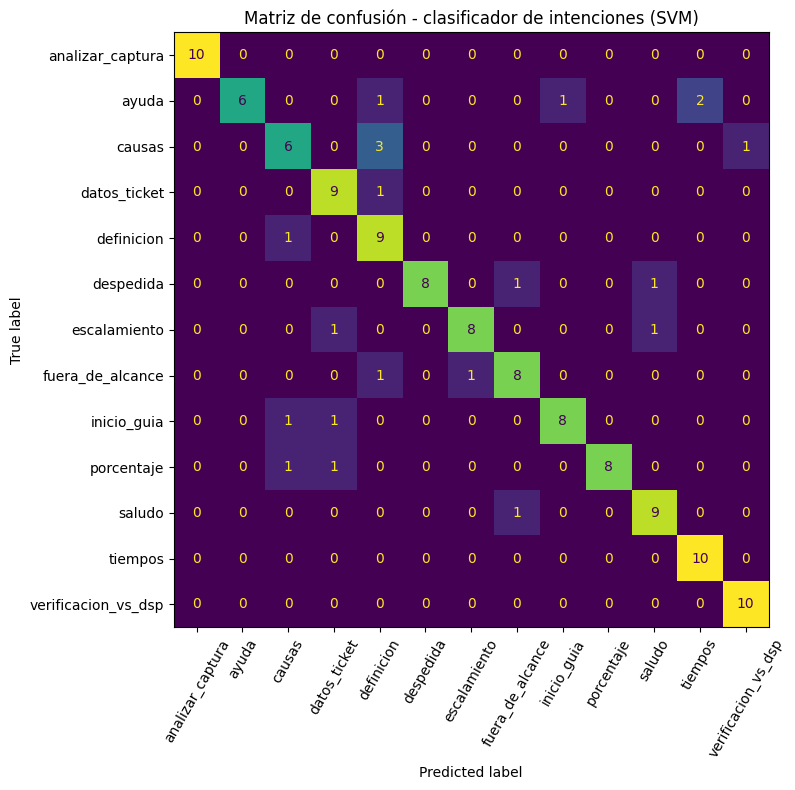

In [10]:
# Celda 4: TF-IDF, entrenamiento de Naive Bayes y SVM, y evaluación

# 1) Separar datos de entrenamiento (75%) y de prueba (25%)
x_train, x_test, y_train, y_test = train_test_split(
    datos["texto_limpio"], datos["intencion"],
    test_size=0.25, random_state=42, stratify=datos["intencion"])
print("Frases de entrenamiento:", len(x_train), "| Frases de prueba:", len(x_test))

# 2) Representación del texto con TF-IDF
vectorizador = TfidfVectorizer()
x_train_tfidf = vectorizador.fit_transform(x_train)
x_test_tfidf = vectorizador.transform(x_test)
print("Tamaño del vocabulario TF-IDF:", len(vectorizador.vocabulary_))

# 3) Entrenar dos clasificadores
modelo_nb = MultinomialNB()
modelo_nb.fit(x_train_tfidf, y_train)

modelo_svm = LinearSVC()
modelo_svm.fit(x_train_tfidf, y_train)

# 4) Evaluar los dos con el conjunto de prueba
nombres_modelos = {"Naive Bayes": modelo_nb, "SVM": modelo_svm}
for nombre in nombres_modelos:
    modelo = nombres_modelos[nombre]
    prediccion = modelo.predict(x_test_tfidf)
    print()
    print("=" * 60)
    print("Modelo:", nombre)
    print("Accuracy:", round(accuracy_score(y_test, prediccion), 3))
    print("Precision (macro):", round(precision_score(y_test, prediccion, average="macro", zero_division=0), 3))
    print("Recall (macro):", round(recall_score(y_test, prediccion, average="macro", zero_division=0), 3))
    print("F1-score (macro):", round(f1_score(y_test, prediccion, average="macro", zero_division=0), 3))

# 5) Validación cruzada (5 particiones) con todo el dataset
todo_tfidf = TfidfVectorizer().fit_transform(datos["texto_limpio"])
print()
print("=" * 60)
for nombre in nombres_modelos:
    puntajes = cross_val_score(type(nombres_modelos[nombre])(), todo_tfidf, datos["intencion"], cv=5)
    print("Validación cruzada", nombre, "->", round(puntajes.mean(), 3))

# 6) Reporte por intención y matriz de confusión del SVM
prediccion_svm = modelo_svm.predict(x_test_tfidf)
print()
print("Reporte por intención (SVM)")
print(classification_report(y_test, prediccion_svm, zero_division=0))

intenciones = sorted(datos["intencion"].unique())
matriz = confusion_matrix(y_test, prediccion_svm, labels=intenciones)
pantalla = ConfusionMatrixDisplay(matriz, display_labels=intenciones)
fig, ax = plt.subplots(figsize=(9, 8))
pantalla.plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.title("Matriz de confusión - clasificador de intenciones (SVM)")
plt.tight_layout()
plt.savefig("matriz_confusion_texto.png", dpi=130)
plt.show()


In [11]:
# Celda 5: prueba con frases nuevas escritas de otra forma (no están en el dataset)
frases_nuevas = [
    ("Muy buenos días, ¿cómo va todo?", "saludo"),
    ("Qué tal, buenas", "saludo"),
    ("No sé qué preguntarte, ¿qué hay disponible?", "ayuda"),
    ("¿Me das un panorama de lo que haces?", "ayuda"),
    ("Oye, ¿qué es eso de discrepancia?", "definicion"),
    ("¿Me puedes aclarar el término discrepancia?", "definicion"),
    ("¿Por qué mis números no son iguales a los del reporte del cliente?", "causas"),
    ("¿Qué hace que las cifras de dos plataformas no concuerden?", "causas"),
    ("¿Cuánta variación entre sistemas se considera normal?", "porcentaje"),
    ("¿Desde qué cifra de diferencia debo avisar?", "porcentaje"),
    ("¿IAS cuenta distinto que el DSP?", "verificacion_vs_dsp"),
    ("¿Qué diferencia hay entre un tag de DV y el conteo del DSP?", "verificacion_vs_dsp"),
    ("Voy a escribir al equipo técnico, ¿qué datos les paso?", "datos_ticket"),
    ("¿Qué le pongo al caso para que lo puedan revisar?", "datos_ticket"),
    ("Es crítico, necesito que alguien lo vea ya", "escalamiento"),
    ("¿Con quién del equipo técnico me comunico?", "escalamiento"),
    ("¿Para cuándo suelen tener respuesta?", "tiempos"),
    ("¿Cuánta espera hay normalmente?", "tiempos"),
    ("Genial, muchas gracias, hasta la próxima", "despedida"),
    ("Con eso es suficiente, gracias", "despedida"),
    ("Ayúdame con el cálculo de la diferencia paso a paso", "inicio_guia"),
    ("Pregúntame los datos y arma el resumen", "inicio_guia"),
    ("Tengo una gráfica de mi campaña, ¿la puedes revisar?", "analizar_captura"),
    ("Te paso un pantallazo del reporte", "analizar_captura"),
    ("¿Qué debería cenar esta noche?", "fuera_de_alcance"),
    ("¿Cómo se juega ajedrez?", "fuera_de_alcance"),
]

textos_nuevos = [f[0] for f in frases_nuevas]
reales = [f[1] for f in frases_nuevas]
limpios = [preprocesar_a_texto(t) for t in textos_nuevos]
vectores = vectorizador.transform(limpios)

resultados = {}
for nombre in nombres_modelos:
    resultados[nombre] = nombres_modelos[nombre].predict(vectores)
    print(nombre, "- accuracy en frases nuevas:", round(accuracy_score(reales, resultados[nombre]), 3))

print()
print("Errores del SVM en las frases nuevas:")
errores = 0
for i in range(len(textos_nuevos)):
    if resultados["SVM"][i] != reales[i]:
        errores = errores + 1
        print(" -", textos_nuevos[i])
        print("     real:", reales[i], "| predicho:", resultados["SVM"][i])
print("Total de errores del SVM:", errores, "de", len(textos_nuevos))


Naive Bayes - accuracy en frases nuevas: 0.769
SVM - accuracy en frases nuevas: 0.808

Errores del SVM en las frases nuevas:
 - ¿Desde qué cifra de diferencia debo avisar?
     real: porcentaje | predicho: causas
 - ¿Con quién del equipo técnico me comunico?
     real: escalamiento | predicho: datos_ticket
 - ¿Cuánta espera hay normalmente?
     real: tiempos | predicho: porcentaje
 - Te paso un pantallazo del reporte
     real: analizar_captura | predicho: inicio_guia
 - ¿Qué debería cenar esta noche?
     real: fuera_de_alcance | predicho: saludo
Total de errores del SVM: 5 de 26


train : 420 imágenes
val : 88 imágenes
test : 92 imágenes
test_estilo_nuevo : 48 imágenes


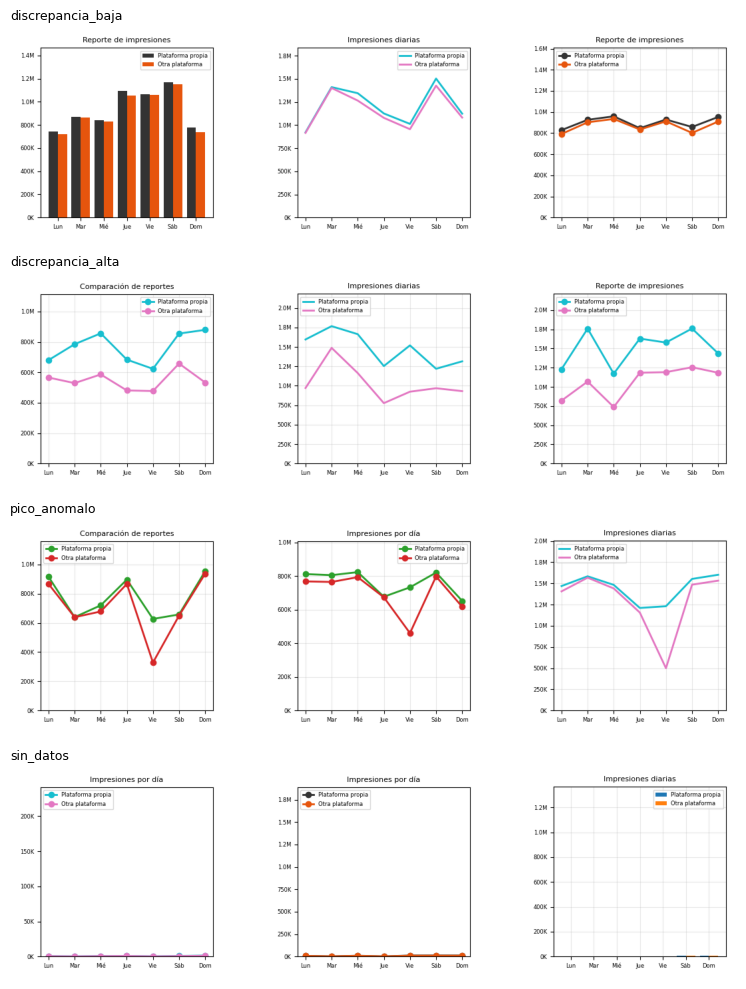

In [12]:
# Celda 6: conjunto de imágenes (capturas de gráficas de un reporte de impresiones)
# Cada imagen compara las impresiones de dos plataformas durante 7 días.
# Clases:
#   discrepancia_baja : las dos líneas casi coinciden (diferencia de 0% a 7%)
#   discrepancia_alta : una plataforma queda siempre por debajo (15% a 40%)
#   pico_anomalo      : diferencia normal, pero 1 o 2 días con una diferencia enorme
#   sin_datos         : reporte vacío (casi cero impresiones)
clases_imagen = ["discrepancia_baja", "discrepancia_alta", "pico_anomalo", "sin_datos"]
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
paletas = [("#1f77b4", "#ff7f0e"), ("#2ca02c", "#d62728"), ("#9467bd", "#8c564b"),
           ("#17becf", "#e377c2"), ("#333333", "#e6550d")]
titulos = ["Impresiones por día", "Reporte de impresiones", "Impresiones diarias", "Comparación de reportes"]
imagenes_por_clase = 150


def formatear_eje(valor, posicion):
    if valor >= 1000000:
        return str(round(valor / 1000000, 1)) + "M"
    return str(int(valor / 1000)) + "K"


def crear_datos(clase):
    # Devuelve las impresiones diarias de la plataforma propia y de la otra plataforma
    volumen = random.uniform(50000, 1500000)
    propia = []
    for d in range(7):
        propia.append(volumen * random.uniform(0.75, 1.25))
    brecha = [random.uniform(0, 0.07) for d in range(7)]

    if clase == "discrepancia_alta":
        brecha = [random.uniform(0.15, 0.40) for d in range(7)]
    if clase == "pico_anomalo":
        dia = random.randint(1, 5)
        brecha[dia] = random.uniform(0.35, 0.70)
        if random.random() < 0.4:
            brecha[dia + 1] = random.uniform(0.30, 0.60)
    if clase == "sin_datos":
        propia = [volumen * random.uniform(0, 0.01) for d in range(7)]
        brecha = [random.uniform(0, 0.3) for d in range(7)]

    otra = []
    for d in range(7):
        otra.append(propia[d] * (1 - brecha[d]))
    return propia, otra, volumen


def dibujar_grafica(propia, otra, volumen, ruta, oscuro=False):
    colores = random.choice(paletas)
    tipo = random.choice(["lineas", "barras", "lineas_puntos"])
    estilo = "dark_background" if oscuro else "default"
    with plt.style.context(estilo):
        fig, ax = plt.subplots(figsize=(3.2, 3.2), dpi=100)
        x = list(range(7))
        if tipo == "barras":
            ax.bar([i - 0.2 for i in x], propia, width=0.4, color=colores[0], label="Plataforma propia")
            ax.bar([i + 0.2 for i in x], otra, width=0.4, color=colores[1], label="Otra plataforma")
        else:
            marcador = "o" if tipo == "lineas_puntos" else None
            ax.plot(x, propia, color=colores[0], marker=marcador, linewidth=2, label="Plataforma propia")
            ax.plot(x, otra, color=colores[1], marker=marcador, linewidth=2, label="Otra plataforma")
        ax.set_ylim(0, volumen * 1.5)
        ax.set_xticks(x)
        ax.set_xticklabels(dias)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(formatear_eje))
        ax.tick_params(labelsize=6)
        ax.set_title(random.choice(titulos), fontsize=8)
        ax.legend(fontsize=6, loc=random.choice(["upper left", "upper right"]))
        if random.random() < 0.5:
            ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(ruta)
        plt.close(fig)


# Crear las carpetas train / val / test (70% / 15% / 15%) y generar las imágenes
for clase in clases_imagen:
    for particion in ["train", "val", "test", "test_estilo_nuevo"]:
        os.makedirs("imagenes/" + particion + "/" + clase, exist_ok=True)

for clase in clases_imagen:
    for i in range(imagenes_por_clase):
        if i < 105:
            particion = "train"
        elif i < 127:
            particion = "val"
        else:
            particion = "test"
        propia, otra, volumen = crear_datos(clase)
        dibujar_grafica(propia, otra, volumen, "imagenes/" + particion + "/" + clase + "/" + str(i) + ".png")

# Prueba extra: 12 imágenes por clase con un estilo visual que el modelo nunca vio (fondo oscuro)
for clase in clases_imagen:
    for i in range(12):
        propia, otra, volumen = crear_datos(clase)
        dibujar_grafica(propia, otra, volumen, "imagenes/test_estilo_nuevo/" + clase + "/" + str(i) + ".png", oscuro=True)

for particion in ["train", "val", "test", "test_estilo_nuevo"]:
    total = 0
    for clase in clases_imagen:
        total = total + len(os.listdir("imagenes/" + particion + "/" + clase))
    print(particion, ":", total, "imágenes")

# Mostrar 3 ejemplos de cada clase
fig, ejes = plt.subplots(4, 3, figsize=(8, 10))
for fila in range(4):
    for col in range(3):
        ruta = "imagenes/train/" + clases_imagen[fila] + "/" + str(col) + ".png"
        ejes[fila][col].imshow(plt.imread(ruta))
        ejes[fila][col].axis("off")
        if col == 0:
            ejes[fila][col].set_title(clases_imagen[fila], fontsize=9, loc="left")
plt.tight_layout()
plt.savefig("muestra_imagenes.png", dpi=110)
plt.show()


In [13]:
# Celda 7: cargar las imágenes y prepararlas para ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.keras.utils.set_random_seed(42)
tamano = (224, 224)   # tamaño de entrada de ResNet50
lote = 32


def cargar(carpeta, mezclar):
    return tf.keras.utils.image_dataset_from_directory(
        carpeta, image_size=tamano, batch_size=lote, label_mode="int",
        shuffle=mezclar, seed=42)


ds_train = cargar("imagenes/train", True)
ds_val = cargar("imagenes/val", False)
ds_test = cargar("imagenes/test", False)
ds_estilo = cargar("imagenes/test_estilo_nuevo", False)

nombres_clases = ds_train.class_names
print("Clases:", nombres_clases)

# Guardar las rutas de las imágenes (se usan después en la integración)
rutas_test = ds_test.file_paths
rutas_estilo = ds_estilo.file_paths


def preparar(imagen, etiqueta):
    # ResNet50 necesita los píxeles en el formato con el que fue entrenada
    return preprocess_input(imagen), etiqueta


ds_train = ds_train.map(preparar)
ds_val = ds_val.map(preparar)
ds_test = ds_test.map(preparar)
ds_estilo = ds_estilo.map(preparar)

Found 420 files belonging to 4 classes.
Found 88 files belonging to 4 classes.
Found 92 files belonging to 4 classes.
Found 48 files belonging to 4 classes.
Clases: ['discrepancia_alta', 'discrepancia_baja', 'pico_anomalo', 'sin_datos']


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 23595908
Parámetros que se entrenan: 8196
Epoch 1/15
14/14 - 95s - 7s/step - accuracy: 0.3119 - loss: 1.6038 - val_accuracy: 0.5341 - val_loss: 1.0458
Epoch 2/15
14/14 - 159s - 11s/step - accuracy: 0.5762 - loss: 0.9770 - val_accuracy: 0.6250 - val_loss: 0.8224
Epoch 3/15
14/14 - 87s - 6s/step - accuracy: 0.6500 - loss: 0.7731 - val_accuracy: 0.6591 - val_loss: 0.7082
Epoch 4/15
14/14 - 91s - 7s/step - accuracy: 0.7167 - loss: 0.6654 - val_accuracy: 0.7273 - val_loss: 0.6617
Epoch 5/15
14/14 - 85s - 6s/step - accuracy: 0.7286 - loss: 0.6308 - val_accuracy: 0.7500 - val_loss: 0.6017
Epoch 6/15
14/14 - 86s - 6s/step - accuracy: 0.7667 - loss: 0.5565 - val_accuracy: 0.8068 - val_loss: 0.5522
Epoch 7/15
14/14 - 90s - 6s/step - accuracy: 0.7762 - loss: 0.5244 - val_accuracy: 0.7841 - val_loss: 0.5488
Epoch 8/15
14/14 - 84s - 6s/step - accuracy: 0.8357 - loss: 0.4423 - val_accuracy: 0.8409 - val_loss: 0.4790
Epoch 9/15
14

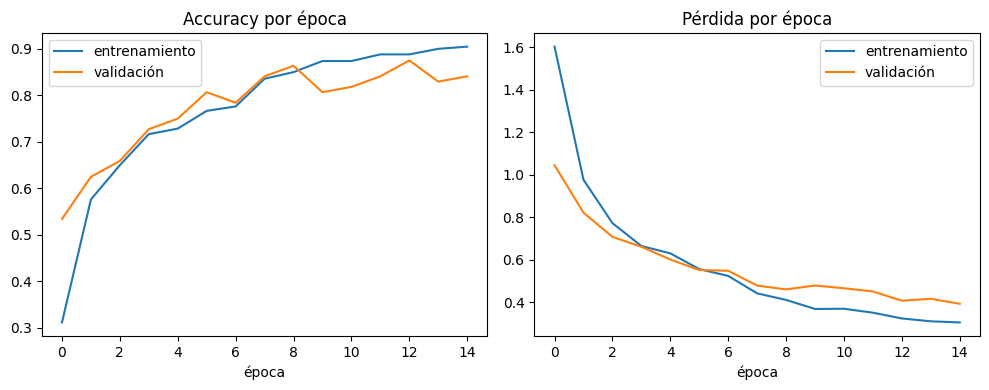

In [14]:
# Celda 8: modelo CNN con transferencia de aprendizaje (ResNet50 preentrenada con ImageNet)
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

# 1) Cargar ResNet50 sin su última capa y congelar sus pesos
base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False

# 2) Agregar nuestras capas para clasificar las 4 clases de gráficas
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(len(nombres_clases), activation="softmax")(x)
modelo = models.Model(inputs=base.input, outputs=salida)

modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

total = modelo.count_params()
entrenables = sum([int(np.prod(w.shape)) for w in modelo.trainable_weights])
print("Parámetros totales:", total)
print("Parámetros que se entrenan:", entrenables)

# 3) Entrenar
historial = modelo.fit(ds_train, validation_data=ds_val, epochs=15, verbose=2)

# 4) Curvas de entrenamiento
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(historial.history["accuracy"], label="entrenamiento")
plt.plot(historial.history["val_accuracy"], label="validación")
plt.title("Accuracy por época")
plt.xlabel("época")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(historial.history["loss"], label="entrenamiento")
plt.plot(historial.history["val_loss"], label="validación")
plt.title("Pérdida por época")
plt.xlabel("época")
plt.legend()
plt.tight_layout()
plt.savefig("curvas_entrenamiento.png", dpi=120)
plt.show()

Matriz de confusión - conjunto de prueba - 92 imágenes
Accuracy: 0.902
Precision (macro): 0.902
Recall (macro): 0.902
F1-score (macro): 0.9

                   precision    recall  f1-score   support

discrepancia_alta       0.92      0.96      0.94        23
discrepancia_baja       0.84      0.91      0.88        23
     pico_anomalo       0.85      0.74      0.79        23
        sin_datos       1.00      1.00      1.00        23

         accuracy                           0.90        92
        macro avg       0.90      0.90      0.90        92
     weighted avg       0.90      0.90      0.90        92



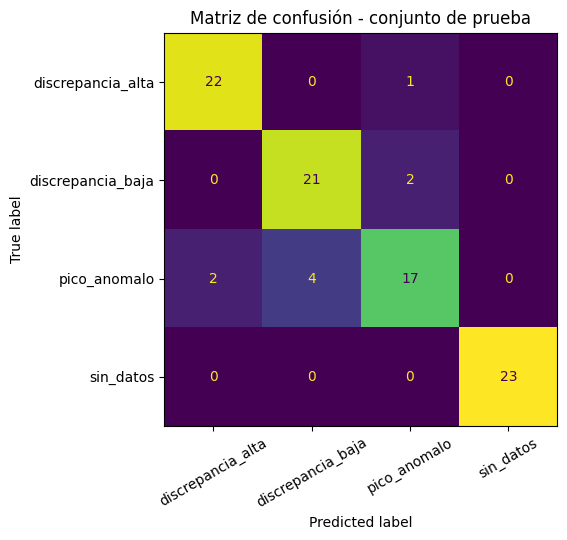

Matriz de confusión - estilo nuevo (fondo oscuro) - 48 imágenes
Accuracy: 0.646
Precision (macro): 0.694
Recall (macro): 0.646
F1-score (macro): 0.604

                   precision    recall  f1-score   support

discrepancia_alta       1.00      0.50      0.67        12
discrepancia_baja       0.44      1.00      0.62        12
     pico_anomalo       0.33      0.08      0.13        12
        sin_datos       1.00      1.00      1.00        12

         accuracy                           0.65        48
        macro avg       0.69      0.65      0.60        48
     weighted avg       0.69      0.65      0.60        48



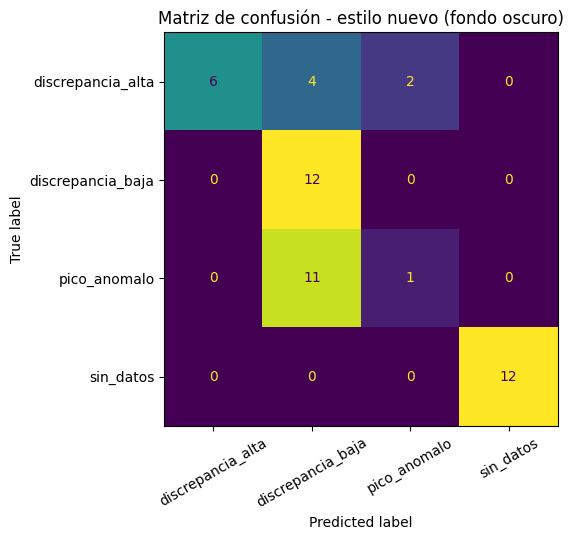

In [15]:
# Celda 9: evaluación del clasificador visual (accuracy, precision, recall, F1 y matriz de confusión)


def evaluar(ds, titulo, archivo):
    reales = []
    predichas = []
    for imagenes, etiquetas in ds:
        probabilidades = modelo.predict(imagenes, verbose=0)
        predichas.extend(np.argmax(probabilidades, axis=1))
        reales.extend(etiquetas.numpy())

    print("=" * 60)
    print(titulo, "-", len(reales), "imágenes")
    print("Accuracy:", round(accuracy_score(reales, predichas), 3))
    print("Precision (macro):", round(precision_score(reales, predichas, average="macro", zero_division=0), 3))
    print("Recall (macro):", round(recall_score(reales, predichas, average="macro", zero_division=0), 3))
    print("F1-score (macro):", round(f1_score(reales, predichas, average="macro", zero_division=0), 3))
    print()
    print(classification_report(reales, predichas, target_names=nombres_clases, zero_division=0))

    matriz = confusion_matrix(reales, predichas, labels=list(range(len(nombres_clases))))
    pantalla = ConfusionMatrixDisplay(matriz, display_labels=nombres_clases)
    fig, ax = plt.subplots(figsize=(6, 5.5))
    pantalla.plot(ax=ax, xticks_rotation=30, colorbar=False)
    plt.title(titulo)
    plt.tight_layout()
    plt.savefig(archivo, dpi=130)
    plt.show()
    return reales, predichas


reales_test, predichas_test = evaluar(ds_test, "Matriz de confusión - conjunto de prueba", "matriz_confusion_imagenes.png")
reales_estilo, predichas_estilo = evaluar(ds_estilo, "Matriz de confusión - estilo nuevo (fondo oscuro)", "matriz_confusion_estilo_nuevo.png")


In [16]:
# Celda 10: integración del chatbot (texto) con el clasificador de imágenes (CNN)

# ---------- Respuestas del chatbot para cada intención ----------
respuestas = {
    "saludo": "¡Hola! Soy el asistente de discrepancias de impresiones. Puedo explicarte qué es una "
              "discrepancia, sus causas, qué porcentaje es normal, qué datos reunir para abrir un "
              "ticket y también revisar la captura de una gráfica de tu reporte. ¿Qué necesitas?",
    "ayuda": "Puedo ayudarte con: (1) qué es una discrepancia, (2) causas comunes, (3) porcentaje "
             "aceptable, (4) diferencia entre verificadores y DSP, (5) datos para abrir un ticket, "
             "(6) cómo escalar, (7) tiempos de respuesta, (8) armar el resumen del ticket (escribe "
             "'guíame') y (9) revisar una captura de tu reporte (adjunta la imagen).",
    "definicion": "Una discrepancia de impresiones es la diferencia entre el número de impresiones "
                  "que reporta un sistema (por ejemplo, tu plataforma) y el que reporta otro (el DSP "
                  "o un verificador externo) para la misma campaña y periodo. Que existan "
                  "diferencias es normal; lo importante es saber si están dentro de un margen razonable.",
    "causas": "Causas comunes: (1) definiciones distintas de 'impresión' (al servir, al renderizar o "
              "al ser visible); (2) filtrado de tráfico inválido (IVT) en un sistema y no en el otro; "
              "(3) latencia o abandono antes de que el anuncio cargue; (4) zonas horarias o cortes de "
              "reporte diferentes; (5) bloqueadores de anuncios o fallas en la etiqueta de medición.",
    "porcentaje": "Como referencia general en la industria, una diferencia de hasta ~10% entre "
                  "sistemas suele considerarse normal. El umbral exacto depende del acuerdo con el "
                  "cliente, así que úsalo como guía y no como regla. Si pasa de ese margen, conviene "
                  "abrir un ticket con los datos de la campaña.",
    "verificacion_vs_dsp": "El DSP (por ejemplo DV360 o The Trade Desk) cuenta lo que compró y sirvió; "
                           "un verificador de terceros (como IAS o DV) mide lo que ocurrió en la página "
                           "con una etiqueta propia. Como miden en momentos y con reglas distintas, sus "
                           "números casi nunca coinciden al 100%. Para comparar, usa el mismo periodo y "
                           "la misma definición de impresión.",
    "datos_ticket": "Para abrir un ticket completo reúne: (1) plataforma o DSP involucrado, (2) rango "
                    "de fechas, (3) impresiones según tu plataforma, (4) impresiones según la otra "
                    "plataforma o verificador, (5) ID de campaña o deal y (6) una captura del reporte. "
                    "Si quieres, escribe 'guíame' y armamos el resumen paso a paso.",
    "escalamiento": "Si es urgente (por ejemplo, una campaña en vuelo con una diferencia muy alta), "
                    "abre el ticket marcándolo como urgente y avisa al equipo de TechOps por el canal "
                    "de soporte interno. Para casos no urgentes basta con el ticket.",
    "tiempos": "Los tiempos dependen de la prioridad y de que el ticket llegue con la información "
               "completa. Un ticket completo se atiende más rápido porque evita preguntas de "
               "seguimiento. Para tiempos exactos, consulta el acuerdo de servicio de tu equipo.",
    "despedida": "¡Con gusto! Si surge otra duda sobre discrepancias, aquí estaré. ¡Hasta pronto!",
    "fuera_de_alcance": "Eso queda fuera de lo que puedo atender. Puedo ayudarte con discrepancias de "
                        "impresiones: definición, causas, porcentaje aceptable, datos para un ticket "
                        "o revisar la captura de una gráfica de tu reporte.",
}

# ---------- Cómo se comunica el resultado del clasificador de imágenes ----------
interpretaciones = {
    "discrepancia_baja": "La gráfica muestra que las dos plataformas están muy cerca una de la otra. "
                         "Parece una diferencia dentro del margen normal (alrededor de 10% o menos), "
                         "así que por ahora no hace falta abrir un ticket.",
    "discrepancia_alta": "La gráfica muestra una diferencia grande y constante entre las dos plataformas "
                         "durante la semana. Parece estar por encima del margen de referencia de 10%. "
                         "Conviene abrir un ticket; si quieres, escribe 'guíame' para armar el resumen.",
    "pico_anomalo": "La gráfica muestra que las plataformas coinciden casi todos los días, pero hay uno "
                    "o dos días con una diferencia muy grande. Anota esas fechas y menciónalas en el "
                    "ticket, porque ayudan a encontrar la causa.",
    "sin_datos": "La gráfica parece vacía o con casi cero impresiones. Antes de abrir un ticket revisa "
                 "que las fechas, los filtros y la campaña del reporte sean correctos.",
}

# ---------- Estado de la conversación ----------
estado = {"paso": None, "datos": {}, "esperando_imagen": False}
pasos_guia = [
    ["plataforma", "Paso 1/4: ¿Con qué plataforma o verificador comparas? (ej. DV360, TTD, IAS)"],
    ["fechas", "Paso 2/4: ¿Qué rango de fechas revisas? (ej. 1 al 7 de octubre)"],
    ["propia", "Paso 3/4: ¿Cuántas impresiones reporta tu plataforma? (solo el número)"],
    ["otra", "Paso 4/4: ¿Cuántas impresiones reporta la otra plataforma? (solo el número)"],
]
margen_referencia = 10


def reiniciar():
    estado["paso"] = None
    estado["datos"] = {}
    estado["esperando_imagen"] = False


# ---------- Componente de texto ----------
def clasificar_texto(texto):
    limpio = preprocesar_a_texto(texto)
    vector = vectorizador.transform([limpio])
    return modelo_svm.predict(vector)[0]


# ---------- Componente visual ----------
def clasificar_imagen(ruta):
    imagen = tf.keras.utils.load_img(ruta, target_size=(224, 224))
    arreglo = tf.keras.utils.img_to_array(imagen)
    arreglo = preprocess_input(np.expand_dims(arreglo, axis=0))
    probabilidades = modelo.predict(arreglo, verbose=0)[0]
    posicion = int(np.argmax(probabilidades))
    return nombres_clases[posicion], float(probabilidades[posicion])


# ---------- Flujo guiado del Avance 1 ----------
def convertir_numero(texto):
    limpio = texto.replace(",", "").replace(".", "").replace(" ", "")
    if limpio.isdigit():
        return int(limpio)
    return None


def paso_guia(texto):
    if texto.strip().lower() == "cancelar":
        reiniciar()
        return "Listo, cancelé el resumen. ¿En qué más te ayudo?"
    nombre = pasos_guia[estado["paso"]][0]
    valor = texto.strip()
    if nombre == "propia" or nombre == "otra":
        valor = convertir_numero(texto)
        if valor is None or valor <= 0:
            return "Necesito solo un número mayor que cero (ej. 1250000). " + pasos_guia[estado["paso"]][1]
    estado["datos"][nombre] = valor
    estado["paso"] = estado["paso"] + 1
    if estado["paso"] < len(pasos_guia):
        return pasos_guia[estado["paso"]][1]
    return armar_resumen()


def armar_resumen():
    d = estado["datos"]
    diferencia = abs(d["propia"] - d["otra"]) / d["propia"] * 100
    if diferencia <= margen_referencia:
        comentario = "dentro del margen de referencia"
    else:
        comentario = "por encima del margen de referencia; conviene abrir el ticket"
    reiniciar()
    return ("Resumen para tu ticket:\n"
            "  - Plataforma: " + d["plataforma"] + "\n"
            "  - Fechas: " + d["fechas"] + "\n"
            "  - Impresiones de tu plataforma: " + format(d["propia"], ",") + "\n"
            "  - Impresiones de la otra plataforma: " + format(d["otra"], ",") + "\n"
            "  - Discrepancia: " + str(round(diferencia, 1)) + "% (" + comentario + ").\n"
            "Recuerda añadir el ID de campaña o deal y una captura del reporte.")


# ---------- Asistente multimodal ----------
def responder(texto, ruta_imagen=None, mostrar_detalle=True):
    # 1) Si hay una imagen adjunta, el componente visual la clasifica
    if ruta_imagen is not None:
        clase, confianza = clasificar_imagen(ruta_imagen)
        if mostrar_detalle:
            print("   [Imagen] clase detectada:", clase, "| confianza:", round(confianza * 100), "%")
        estado["esperando_imagen"] = False
        mensaje = interpretaciones[clase]
        if confianza < 0.6:
            mensaje = ("No estoy muy seguro de esta imagen (confianza baja), así que revisa la "
                       "gráfica con cuidado. Mi mejor estimación: " + mensaje)
        return "Revisé tu imagen. " + mensaje

    # 2) Mensaje vacío
    if texto.strip() == "":
        return "Escribe tu pregunta y con gusto te ayudo."

    # 3) Si el flujo guiado está activo, el texto es la respuesta a la pregunta anterior
    if estado["paso"] is not None:
        return paso_guia(texto)

    # 4) El componente de texto detecta la intención
    intencion = clasificar_texto(texto)
    if mostrar_detalle:
        print("   [Texto] intención detectada:", intencion)

    if intencion == "analizar_captura":
        estado["esperando_imagen"] = True
        return "Claro. Adjunta la imagen de la gráfica de tu reporte y te digo qué tipo de discrepancia muestra."
    if intencion == "inicio_guia":
        estado["paso"] = 0
        estado["datos"] = {}
        return "Perfecto, armemos el resumen. (Escribe 'cancelar' para salir.)\n" + pasos_guia[0][1]
    return respuestas[intencion]


def simular(turnos, titulo=""):
    # turnos: lista de (texto, ruta_imagen). Si no hay imagen se usa None
    reiniciar()
    print("=" * 72)
    print(titulo)
    for texto, ruta in turnos:
        if ruta is None:
            print("Usuario:", texto)
        else:
            print("Usuario:", texto, " [adjunta:", ruta, "]")
        print("Bot:", responder(texto, ruta))
    print()


In [17]:
# Celda 11: conversaciones de prueba que usan texto e imágenes

# Elegir una imagen de prueba de cada clase (estas imágenes no se usaron para entrenar)
def imagen_de(clase):
    for ruta in rutas_test:
        if "/" + clase + "/" in ruta:
            return ruta


img_alta = imagen_de("discrepancia_alta")
img_baja = imagen_de("discrepancia_baja")
img_pico = imagen_de("pico_anomalo")
img_vacia = imagen_de("sin_datos")

# Buscar una imagen del conjunto de estilo nuevo que el modelo clasifique mal
img_dificil = None
clase_real_dificil = None
for i in range(len(rutas_estilo)):
    if predichas_estilo[i] != reales_estilo[i] and img_dificil is None:
        img_dificil = rutas_estilo[i]
        clase_real_dificil = nombres_clases[reales_estilo[i]]

simular([("Hola, buenas tardes", None),
         ("Quiero analizar una captura de mi reporte", None),
         ("Aquí está la imagen", img_alta),
         ("Gracias, eso era todo", None)],
        "M1 - Saludo, solicitud de análisis y resultado: discrepancia alta")

simular([("Revisa esta gráfica de impresiones por favor", img_pico)],
        "M2 - Imagen con un pico anómalo")

simular([("Te mando la gráfica de mi campaña", img_baja),
         ("¿Qué porcentaje de diferencia es aceptable?", None)],
        "M3 - Imagen con discrepancia baja y pregunta de seguimiento")

simular([("Analiza esta captura", img_vacia)],
        "M4 - Imagen de un reporte vacío")

simular([("Tengo una gráfica de mi reporte", None),
         ("Adjunto la imagen", img_alta),
         ("Guíame para armar el resumen", None),
         ("DV360", None),
         ("1 al 7 de octubre", None),
         ("900,000", None),
         ("700,000", None)],
        "M5 - De la imagen al resumen del ticket (flujo guiado, datos ficticios)")

simular([("¿Por qué no coinciden los números entre plataformas?", None),
         ("¿Cuál es la capital de Francia?", None)],
        "M6 - Solo texto: pregunta del dominio y pregunta fuera de alcance")

if img_dificil is not None:
    simular([("Revisa esta captura", img_dificil)],
            "M7 - Caso difícil: imagen de estilo nuevo (la clase real era: " + clase_real_dificil + ")")


M1 - Saludo, solicitud de análisis y resultado: discrepancia alta
Usuario: Hola, buenas tardes
   [Texto] intención detectada: saludo
Bot: ¡Hola! Soy el asistente de discrepancias de impresiones. Puedo explicarte qué es una discrepancia, sus causas, qué porcentaje es normal, qué datos reunir para abrir un ticket y también revisar la captura de una gráfica de tu reporte. ¿Qué necesitas?
Usuario: Quiero analizar una captura de mi reporte
   [Texto] intención detectada: analizar_captura
Bot: Claro. Adjunta la imagen de la gráfica de tu reporte y te digo qué tipo de discrepancia muestra.
Usuario: Aquí está la imagen  [adjunta: imagenes/test/discrepancia_alta/127.png ]
   [Imagen] clase detectada: discrepancia_alta | confianza: 69 %
Bot: Revisé tu imagen. La gráfica muestra una diferencia grande y constante entre las dos plataformas durante la semana. Parece estar por encima del margen de referencia de 10%. Conviene abrir un ticket; si quieres, escribe 'guíame' para armar el resumen.
Usuari

In [18]:
# Celda 12 (opcional): conversar con el asistente y subir tus propias imágenes en Colab
# Quita el # de las últimas líneas para usarla.
def chatear():
    reiniciar()
    print("Bot: Hola, soy el asistente de discrepancias. Escribe 'salir' para terminar.")
    print("     Para analizar una imagen, escribe 'imagen' y súbela cuando se pida.")
    while True:
        entrada = input("Tú: ")
        if entrada.strip().lower() == "salir" and estado["paso"] is None:
            print("Bot: ¡Hasta pronto!")
            break
        if entrada.strip().lower() == "imagen":
            from google.colab import files
            subidos = files.upload()
            for nombre in subidos:
                print("Bot:", responder("Adjunto una imagen", nombre))
        else:
            print("Bot:", responder(entrada))


# chatear()
